# Exploring your saved backtests

Every time you test a stock-picking rule ("a portfolio") with screenlab, you can have it write down **what you asked, which data it used, and the numbers that came out**. That record is a *run store*: one small database file. This notebook runs a handful of backtests into a store and then shows how to look things up, compare them, plot them and repeat them.

**Where the file goes.** The store is a file called `runs.sqlite` created **next to this notebook** (change `STORE_PATH` in the next cell to put it elsewhere, for example in a temporary folder). Nothing is sent anywhere. The file is excluded from git (`screenlab/.gitignore`), and the notebook deletes and recreates it each time it is run from the top, so you always get a clean demonstration. Set `START_FRESH = False` to keep adding to an existing file instead.

**One rule throughout:** a portfolio is only meaningful next to a passive alternative. Every table and chart below includes the passive S&P 500 index (buy once and hold) next to the portfolios.

In [1]:
import sys, time, sqlite3
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

try:
    import screenlab
except ImportError:                       # running from a git checkout without installing the package
    sys.path.insert(0, str(Path.cwd().parent.parent))
    import screenlab
from screenlab import Lab, SQLiteStore, ExitPolicy, ExitScreen, TrendBreak
from screenlab.jobs import execute_spec
from screenlab.runspec import dataset_id
from screenlab.realdata.bundled import sp500_lab

# ---- settings you may change -------------------------------------------------------------
STORE_PATH = Path("runs.sqlite")          # relative to this notebook's folder
START_FRESH = True                        # True: delete the file first, so every run of the notebook is identical
# -------------------------------------------------------------------------------------------

if START_FRESH:
    for suffix in ("", "-wal", "-shm"):
        Path(str(STORE_PATH) + suffix).unlink(missing_ok=True)

pd.options.display.float_format = "{:,.3f}".format
pd.options.display.width = 140
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
t_start = time.time()
print("store file:", STORE_PATH.resolve())

store file: /home/user/datasharing/screenlab/notebooks/runs.sqlite


## 1. Open the store and the data

`SQLiteStore(path)` creates the file if needed. We hand it to a `Lab` (the object that holds data, portfolios and settings) with `persist="full"`, which means: keep the inputs, the summary numbers **and** the full equity curves (the value of $1 invested over time) of every run.

The data are the 20 large US stocks and the S&P 500 index bundled with the package, daily from 1990 to 2022. The S&P 500 series bundled with the package is a *price* index (dividends are not included), which would understate the passive alternative by roughly 2% a year and flatter every portfolio. `sp500_lab()` therefore adds an assumed 2% a year of dividends to it, so the benchmark below is labelled *SP500 +2.0% div (approx. TR)*: an approximation, not real total-return data. A bare price index as the benchmark is refused unless you pass `allow_price_benchmark=True`.

In [2]:
store = SQLiteStore(STORE_PATH)
lab = sp500_lab(store=store, persist="full")
lab.name = "sp500"                         # the name recorded with each run
print(lab.market.prices.shape[1], "stocks,", lab.market.index[0].date(), "to", lab.market.index[-1].date())
print("passive benchmark:", lab.benchmark.label)

20 stocks, 1990-01-02 to 2022-12-28
passive benchmark: SP500 +2.0% div (approx. TR)


## 2. Two portfolios, with and without a safety exit

* **momentum_12_1** buys the 5 stocks that rose the most over the past year (ignoring the latest month).
* **low_vol** buys the 5 stocks whose prices have been calmest.

Both rebalance every month, equal-weighted (we also run the same thing rebalancing every 3 months, to compare in section 7). For each we also run a version with the **fixed trend exit** recommended in `research/CALIBRATION_SP500.md`: when the S&P 500 is weak against its own 10-month average (checked weekly, score above 0.8, held at least 10 days), sell everything to cash, and buy back when the signal clears. That setting was chosen in advance, not fitted to the data. In that study it cut the worst loss by roughly a quarter to a half at about the same return, but the evidence is thin (it rests on four crashes).

With `with_and_without=True` the table has a row `name` (no exit) and `name+exit`. `TimeOut` is the share of days spent out of the market; `Switches/yr` how often it moved in or out.

**How to read the table.** `CAGR` is the average yearly growth, `Vol` the typical size of the ups and downs, `Sharpe` return per unit of ups and downs, `MaxDD` the worst fall from a peak, and `Excess/yr` the yearly growth above the passive index (the `SP500` row is the index itself, so its excess is zero). Percentages are shown for readability; in the database they are stored as plain decimals (0.12 = 12%).

In [3]:
exit_policy = ExitPolicy(
    ExitScreen([TrendBreak("SP500")], threshold=0.8, hysteresis=0.1, check="W-FRI", min_hold_days=10),
    exposure_when_flagged=0.0,             # go fully to cash while the flag is up
)

def show(table, cols=("CAGR", "Vol", "Sharpe", "MaxDD", "Excess/yr", "TimeOut", "Switches/yr")):
    pct = {"CAGR", "Vol", "MaxDD", "Excess/yr", "TimeOut"}
    t = table[[c for c in cols if c in table]]
    return t.apply(lambda s: s.map(lambda x: "" if pd.isna(x) else (f"{x:.1%}" if s.name in pct else f"{x:.2f}")))

t0 = time.time()
both = ["momentum_12_1", "low_vol"]
rep_m = lab.backtest(both, rebalance_months=1, exit=exit_policy, with_and_without=True)   # monthly
rep_q = lab.backtest(both, rebalance_months=3, exit=exit_policy, with_and_without=True)   # quarterly, for comparison
print(f"two backtests in {time.time() - t0:.0f}s (monthly shown)")
show(rep_m.table)

two backtests in 18s (monthly shown)


,CAGR,Vol,Sharpe,MaxDD,Excess/yr,TimeOut,Switches/yr
SP500 +2.0% div (approx. TR),9.9%,18.4%,0.61,-55.5%,,,
momentum_12_1,22.8%,23.8%,0.98,-47.2%,12.9%,,
momentum_12_1+exit,19.4%,18.7%,1.04,-33.2%,9.5%,25.1%,2.41
low_vol,12.7%,15.3%,0.86,-35.1%,2.8%,,
low_vol+exit,10.1%,11.1%,0.92,-17.8%,0.2%,25.1%,2.41


## 3. A third backtest on made-up data

The runs above use the S&P 500 screens, which are ordinary Python functions in `screenlab.realdata.bundled`. Because each is a function that can be imported by name, the store records it as a reference (`module:function`) and can rebuild it later, so those runs are fully repeatable. (A screen defined as a `lambda`, inside another function, or in a notebook cell cannot be rebuilt this way and is stored without a key.) For contrast this section also runs the built-in *synthetic* (computer-generated) market with screens defined as data (`dogs`, `graham_defensive`). It is made-up data: its returns say nothing about real markets.

In [4]:
from screenlab.screens import REGISTRY           # whatever screens the package currently ships

syn = Lab.synthetic(freq="ME", n_stocks=150, years=10, seed=3, store=store, persist="full")
syn.name = "synthetic"
syn_screens = [n for n in ("dogs", "graham_defensive") if n in REGISTRY]
rep_syn = syn.backtest(syn_screens, rebalance_months=6)
show(rep_syn.table)

,CAGR,Vol,Sharpe,MaxDD,Excess/yr
SYN_CAPWT,9.4%,17.8%,0.60,-26.6%,
dogs,7.7%,19.7%,0.47,-38.6%,-1.8%
graham_defensive,1.9%,6.2%,0.34,-7.1%,-7.5%


## 4. A long study as a background job

A *timing study* asks: if I ran the same monthly strategy but started on a different day each time, how much would the result change purely by luck of the calendar? Done for every start day it takes minutes, so it can run as a **job** in the background while you do other things. Here we use a coarse stride (every 7th trading day) so it finishes in seconds.

`lab.submit(...)` returns at once with a job object; we poll its `status` and `progress` until it is done.

In [5]:
job = lab.submit("timing", screen="momentum_12_1", stride=7, rebalance_months=1,
                 label="timing: momentum_12_1, monthly", tags=("timing", "momentum"))
print("submitted:", job)
while job.status in ("queued", "running"):
    print(f"  {job.status:8s} {job.progress:4.0%}  {job.message}")
    time.sleep(1.0)
print("final:   ", job.status, f"{job.progress:.0%}")
timing = job.result()                       # the same object lab.timing(...) would have returned
# the table summarises the spread across start days; `range` = biggest minus smallest value, so a wide CAGR
# range means the answer depended heavily on when you happened to begin
print(f"{len(timing.table)} different start days")
timing.distribution().round(3)

submitted: Job(47a40028, timing, running, 0%)
  running    0%  


  running   20%  offset 1/3: momentum_12_1: rebalance 235/383


  running   35%  offset 2/3: momentum_12_1: rebalance 18/384


  running   40%  offset 2/3: momentum_12_1: rebalance 78/384


  running   46%  offset 2/3: momentum_12_1: rebalance 143/384


...

  running   86%  offset 3/3: momentum_12_1: rebalance 227/384


  running   91%  offset 3/3: momentum_12_1: rebalance 283/384


  running   96%  offset 3/3: momentum_12_1: rebalance 335/384


final:    done 100%
3 different start days


,mean,std,min,5%,25%,50%,75%,95%,max,range
CAGR,0.228,0.012,0.216,0.217,0.222,0.228,0.234,0.240,0.241,0.025
Excess/yr,0.129,0.012,0.117,0.118,0.123,0.129,0.135,0.140,0.142,0.025
MaxDD,-0.468,0.016,-0.481,-0.480,-0.477,-0.472,-0.461,-0.453,-0.451,0.031
Vol,0.238,0.001,0.238,0.238,0.238,0.239,0.239,0.239,0.239,0.001
BeatBenchYrs,0.792,0.036,0.750,0.756,0.781,0.812,0.812,0.812,0.812,0.062


## 5. What is in the store? List the runs

The store is a normal SQLite file with a few tables: `runs` (one row per analysis), `metrics` (the numbers), `artifacts` (curves and other bulky tables), `datasets`, `trials` and `jobs`. The column-by-column description is in `screenlab/schema/runstore.linkml.yaml`.

In the list: `status` is `done` once the run finished; `level` says how much was kept (`full` includes curves); `rerunnable` is 1 when the run can be repeated from the store. The timing job appears here as a run of kind `timing`.

In [6]:
con = sqlite3.connect(STORE_PATH)
runs = pd.read_sql_query(
    "SELECT substr(run_key, 1, 22) AS run_key, kind, status, persist_level AS level, persistable AS rerunnable, "
    "       datetime(created_at, 'unixepoch') AS started, screens, label FROM runs ORDER BY created_at", con)
runs

,run_key,kind,status,level,rerunnable,started,screens,label
0,9e2b72c706f528bd94e514,backtest,done,full,1,2026-10-29 03:55:09,",low_vol,momentum_12_1,",NaN
1,8f65ff32d9296af105a3b3,backtest,done,full,1,2026-10-29 03:55:12,",low_vol,momentum_12_1,",NaN
2,d7eefbeb18c23d6a6d4d06,backtest,done,full,1,2026-10-29 03:55:13,",dogs,graham_defensive,",NaN
3,556f8fe2d6fa4aab7edf84,timing,done,full,1,2026-10-29 03:55:13,",momentum_12_1,","timing: momentum_12_1, monthly"


## 6. One tidy table of numbers: runs by measures

`store.find(...)` returns one row per portfolio per run with one column per measure. Here we keep the backtests and put the run in front, so the whole history reads as a single table. (`where={"Excess/yr": (">", 0.02)}` would keep only rows that beat the index by more than 2% a year.) Some cells are blank: `TimeOut` and `Switches/yr` only exist for rows with an exit policy. Because the numbers are plain decimals you can sort and filter them like any table.

In [7]:
tidy = store.find(kind="backtest")
tidy["run"] = tidy["dataset"] + " #" + (tidy.groupby("run_key", sort=False).ngroup() + 1).astype(str)
cols = ["CAGR", "Vol", "Sharpe", "MaxDD", "Worst12m", "BeatBenchYrs", "Excess/yr", "Turnover", "Costs/yr", "TimeOut", "Switches/yr"]
wide = tidy.set_index(["run", "row_label"])[[c for c in cols if c in tidy]]
wide

CAGR   Vol  Sharpe  MaxDD  Worst12m  BeatBenchYrs  Excess/yr  Turnover  Costs/yr  TimeOut  \
run          row_label                                                                                                                 
sp500 #1     SP500 +2.0% div (approx. TR) 0.099 0.184   0.607 -0.555    -0.478           NaN        NaN       NaN       NaN      NaN   
             low_vol                      0.127 0.153   0.856 -0.351    -0.283         0.562      0.028     0.072     0.004      NaN   
             low_vol+exit                 0.101 0.111   0.921 -0.178    -0.130         0.406      0.002     0.072     0.003    0.251   
             momentum_12_1                0.228 0.238   0.983 -0.472    -0.406         0.812      0.129     0.250     0.015      NaN   
             momentum_12_1+exit           0.194 0.187   1.043 -0.332    -0.275         0.625      0.095     0.250     0.011    0.251   
sp500 #2     SP500 +2.0% div (approx. TR) 0.099 0.184   0.607 -0.555    -0.478           NaN        NaN       NaN       NaN      NaN   
             low_vol                      0.118 0.154   0.800 -0.355    -0.281         0.531      0.018     0.134     0.003      NaN   
             low_vol+exit                 0.096 0.112   0.875 -0.235    -0.200         0.375     -0.003     0.134     0.002    0.251   
             momentum_12_1                0.251 0.241   1.048 -0.443    -0.392         0.688      0.151     0.390     0.008      NaN   
             momentum_12_1+exit           0.210 0.186   1.120 -0.306    -0.260         0.656      0.111     0.390     0.006    0.251   
synthetic #3 SYN_CAPWT                    0.094 0.178   0.595 -0.266    -0.231           NaN        NaN       NaN       NaN      NaN   
             dogs                         0.077 0.197   0.472 -0.386    -0.358         0.333     -0.018     0.514     0.005      NaN   
             graham_defensive             0.019 0.062   0.341 -0.071    -0.009         0.222     -0.075     0.029     0.001      NaN   

                                           Switches/yr  
run          row_label                                  
sp500 #1     SP500 +2.0% div (approx. TR)          NaN  
             low_vol                               NaN  
             low_vol+exit                        2.414  
             momentum_12_1                         NaN  
             momentum_12_1+exit                  2.414  
sp500 #2     SP500 +2.0% div (approx. TR)          NaN  
             low_vol                               NaN  
             low_vol+exit                        2.414  
             momentum_12_1                         NaN  
             momentum_12_1+exit                  2.414  
synthetic #3 SYN_CAPWT                             NaN  
             dogs                                  NaN  
             graham_defensive                      NaN

## 7. Side by side with `store.compare`

`store.compare([key1, key2, ...])` puts chosen runs in adjacent columns; here, the same four portfolios rebalanced monthly versus quarterly (with the index for reference). It works best for runs that share portfolio names. Give runs a short name first (the `label`) so the columns are readable; the label is only a note and does not change the run's identity.

In [8]:
def key_of(kind, nth=-1, **where):
    rows = store.find(kind=kind, **where)
    return rows["run_key"].drop_duplicates().tolist()[nth]

keys = {"sp500 monthly":   key_of("backtest", 0, dataset="sp500"),
        "sp500 quarterly": key_of("backtest", 1, dataset="sp500"),
        "synthetic":       key_of("backtest", dataset="synthetic")}
with sqlite3.connect(STORE_PATH) as c:                        # name the runs
    for label, k in keys.items():
        c.execute("UPDATE runs SET label=? WHERE run_key=?", (label, k))
store.compare([keys["sp500 monthly"], keys["sp500 quarterly"]], metrics=["CAGR", "Sharpe", "MaxDD", "Excess/yr"])

sp500 monthly  sp500 quarterly
row_label                    metric                                   
SP500 +2.0% div (approx. TR) CAGR               0.099            0.099
                             Sharpe             0.607            0.607
                             MaxDD             -0.555           -0.555
                             Excess/yr            NaN              NaN
momentum_12_1                CAGR               0.228            0.251
                             Sharpe             0.983            1.048
                             MaxDD             -0.472           -0.443
                             Excess/yr          0.129            0.151
momentum_12_1+exit           CAGR               0.194            0.210
                             Sharpe             1.043            1.120
                             MaxDD             -0.332           -0.306
                             Excess/yr          0.095            0.111
low_vol                      CAGR               0.127            0.118
                             Sharpe             0.856            0.800
                             MaxDD             -0.351           -0.355
                             Excess/yr          0.028            0.018
low_vol+exit                 CAGR               0.101            0.096
                             Sharpe             0.921            0.875
                             MaxDD             -0.178           -0.235
                             Excess/yr          0.002           -0.003

## 8. How many things have I tried? The trial counter

The more variations you test, the more likely the best-looking one is just lucky. The store counts every distinct run, grouped into a *family* (same kind of analysis, same data, same screens), and uses that count to deflate the Sharpe ratio in significance tests (`DSR`). The table shows the counts so far. Repeating an identical run does not count twice; each new variation does. The S&P 500 backtests are counted like any other: monthly and quarterly rebalancing of the same two screens are two distinct runs of one family.

In [9]:
trials = pd.read_sql_query(
    "SELECT family, COUNT(DISTINCT run_key) AS distinct_runs FROM trials GROUP BY family ORDER BY family", con)
# repeating an identical run does not add a trial; a new variation does
before = lab.last_trials()["trials_in_family"] if lab.last_trials() else None
lab.backtest(both, rebalance_months=1, exit=exit_policy, with_and_without=True)           # identical to rep_m
same = lab.last_trials()["trials_in_family"]
lab.backtest(both, rebalance_months=2, exit=exit_policy, with_and_without=True)           # a new variation
print("trials in the family: before", before, "| after repeating a run", same, "| after a new variation", lab.last_trials()["trials_in_family"])
trials

trials in the family: before 2 | after repeating a run 2 | after a new variation 3


,family,distinct_runs
0,backtest|sp500|low_vol+momentum_12_1,2
1,backtest|synthetic|dogs+graham_defensive,1
2,timing|sp500|momentum_12_1,1


## 9. Plot the stored equity curves against the passive index

Because we used `persist="full"`, the value-of-$1 curves were saved too. They come back as ordinary tables with `store.artifact(run_key, "curves")`. The grey line is the passive S&P 500 index (bought once, never touched); it is in every panel. Vertical scales are logarithmic so equal percentage moves look equal. The exit version (orange) trades some growth for shallower falls in 2000-02, 2008 and 2020; being ahead of or behind the grey line over one period proves little, and the research note explains why the evidence is thin.

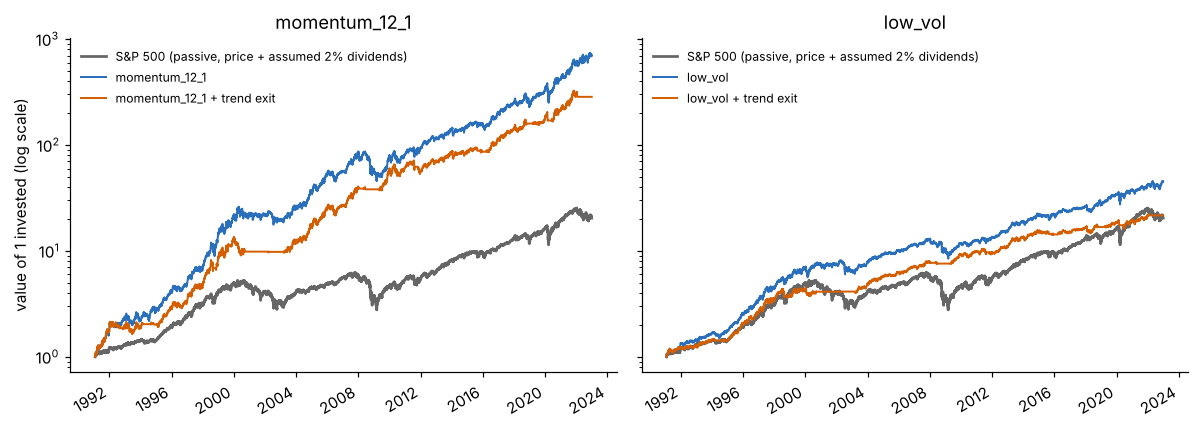

In [10]:
panels = [("sp500 monthly", "momentum_12_1"), ("sp500 monthly", "low_vol")]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
colors = {"plain": "#2a6fbb", "exit": "#d55e00"}
for ax, (label, name) in zip(axes, panels):
    curves = store.artifact(keys[label], "curves")
    curves = curves / curves.iloc[0]
    curves[lab.benchmark.label].plot(ax=ax, color="#666666", lw=1.8, label="S&P 500 (passive, price + assumed 2% dividends)")
    curves[name].plot(ax=ax, color=colors["plain"], lw=1.3, label=name)
    curves[name + "+exit"].plot(ax=ax, color=colors["exit"], lw=1.3, label=name + " + trend exit")
    ax.set_yscale("log"); ax.set_title(name); ax.set_xlabel(""); ax.legend(frameon=False, fontsize=8, loc="upper left")
axes[0].set_ylabel("value of 1 invested (log scale)")
plt.tight_layout(); plt.show()

## 10. Ask the file questions directly with SQL

The store is plain SQLite, so any tool can read it, for example `pandas.read_sql_query` as below, a spreadsheet add-in, or the `sqlite3` command line. This query lists every stored portfolio that beat the passive index by more than 2% a year *and* never fell more than 50% from a peak. Remember that the metric names are the labels in the `metric` column; the run is joined by `run_key`.

In [11]:
sql = '''
SELECT r.label, m.row_label AS portfolio,
       ROUND(ex.value, 3) AS excess_per_year, ROUND(dd.value, 3) AS max_drawdown
FROM runs r
JOIN metrics ex ON ex.run_key = r.run_key AND ex.metric = 'Excess/yr'
JOIN metrics dd ON dd.run_key = r.run_key AND dd.row_label = ex.row_label AND dd.metric = 'MaxDD'
JOIN metrics m  ON m.run_key  = r.run_key AND m.row_label  = ex.row_label AND m.metric  = 'CAGR'
WHERE r.kind = 'backtest' AND ex.value > 0.02 AND dd.value > -0.50
ORDER BY ex.value DESC
'''
pd.read_sql_query(sql, con)

,label,portfolio,excess_per_year,max_drawdown
0,sp500 quarterly,momentum_12_1,0.151,-0.443
1,sp500 monthly,momentum_12_1,0.129,-0.472
2,NaN,momentum_12_1,0.124,-0.486
3,sp500 quarterly,momentum_12_1+exit,0.111,-0.306
4,sp500 monthly,momentum_12_1+exit,0.095,-0.332
5,NaN,momentum_12_1+exit,0.088,-0.306
6,NaN,low_vol,0.028,-0.350
7,sp500 monthly,low_vol,0.028,-0.351


## 11. Repeat a stored run and check it reproduces

`store.rerun(run_key, executor)` rebuilds the inputs from the stored record, recomputes, and compares with the stored numbers. A `match` of `True` means the same inputs, data and code give the same answer, which is the point of keeping the record. It also tells you whether the data (`dataset_changed`) or the program (`code_changed`) differ from when the run was made. Here we repeat the monthly S&P 500 backtest, whose screens are rebuilt from their stored function references.

In [12]:
report = store.rerun(keys["sp500 monthly"], lambda spec: execute_spec(spec, lab), dataset_id=dataset_id(lab.market))
print("numbers identical:", report.match, "| largest difference:", report.max_abs_diff)
print("data changed:", report.dataset_changed, "| code changed:", report.code_changed)

numbers identical: True | largest difference: 0.0
data changed: False | code changed: False


## 12. Where to go next

* The store file is `runs.sqlite` next to this notebook. Open it in any SQLite viewer, or keep adding runs from your own scripts with `Lab(..., store=SQLiteStore("runs.sqlite"))`.
* `store.find(kind=..., screen=..., where={"Sharpe": (">", 1)})` filters; `store.export("backup.csv")` or `.json` writes a copy; `store.prune(keep_last=50)` cleans up.
* Column names, units and the meaning of every value are in `screenlab/schema/runstore.linkml.yaml`.

In [13]:
con.close(); store.close()
print(f"notebook body ran in {time.time() - t_start:.0f}s; file size {STORE_PATH.stat().st_size / 1e6:.1f} MB")

notebook body ran in 59s; file size 0.0 MB
